# M10 Overview | Custom Backend: Writing Hardware Constraints as a Quantizer

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/bobondemon/pt2e_quantize_and_deploy/blob/main/en/m10_custom_backend/00_overview.ipynb)

The backends in M08 and M09 are forgiving: they accept per-channel, asymmetric activations, arbitrary scales and dynamic batch, and any op without an int8 version stays in fp32. VPU/NPU-class hardware is usually much narrower ("How a CPU Differs from a VPU/NPU" in the [M09 overview](../m09_onnx_runtime/00_overview.ipynb)).

This chapter moves to the backend author's side: invent a VPU and do the three things a backend has to hand over.

| What the backend author does | How this chapter does it | notebook |
|---|---|---|
| Give algorithm engineers a Quantizer | Write the eight hardware constraints as `MyVPUQuantizer` | M10-1 |
| Check the graph before consuming it | A checker pass `check_vpu` that reads only the Q/DQ graph | M10-2 |
| Fall back unsupported ops to CPU | A minimal partitioner `partition` that prints the partitioned graph | M10-3 |

The backend itself is in [`vpu_quantizer.py`](vpu_quantizer.py): a file of this project, not a torchao API, and not a notebook. The M10 notebooks import it with `from vpu_quantizer import …`. The VPU is fictional; the constraints are common requirements of this kind of hardware (general knowledge), and this project has no real device.

In [1]:
#| include: false
# On Google Colab: download this course's code and install the packages (takes a few minutes the first time).
# On your own machine (see the README for the environment), this cell does nothing.
import sys

if "google.colab" in sys.modules:
    import os
    import subprocess

    repo = "/content/pt2e_quantize_and_deploy"
    if not os.path.exists(repo):
        subprocess.run(["git", "clone", "-q", "--depth", "1",
                        "https://github.com/bobondemon/pt2e_quantize_and_deploy.git", repo], check=True)
        subprocess.run([sys.executable, "-m", "pip", "install", "-q",
                        "--extra-index-url", "https://download.pytorch.org/whl/cpu",
                        "torch==2.14.0+cpu", "torchao==0.18.0", "onnx==1.23.0", "onnxscript==0.7.2",
                        "onnxruntime==1.30.0", "tabulate", "graphviz"], check=True)
    sys.path.insert(0, repo)  # so the notebook can import this course's common/
    os.chdir(f"{repo}/en/m10_custom_backend")

In [2]:
#| echo: false
import torch

from common.pt2e import convert_pt2e, export_module, get_xnnpack_quantizer, prepare_pt2e, quiet
from common.data import calibration_batches
from common.models import example_inputs, get_model
from common.viz import draw
from vpu_quantizer import MyVPUQuantizer

quiet()
_ = torch.manual_seed(0)

## An Example First: the Same conv + relu, the Q/DQ Graphs of Two Backends

Take the smallest conv + relu and run PTQ with `MyVPUQuantizer` and with the torchao test-version XNNPACKQuantizer. The VPU takes static shapes only, so both sides use `export_module(..., dynamic_batch=False)`, and the calibration batch size equals the export batch size:

In [3]:
def ptq(quantizer):
    model, x = get_model("conv_relu").eval(), example_inputs(16)
    prepared = prepare_pt2e(export_module(model, x, dynamic_batch=False), quantizer)
    with torch.no_grad():
        for batch in calibration_batches(64, batch_size=16):
            prepared(*batch)
    return convert_pt2e(prepared)


vpu = ptq(MyVPUQuantizer())
xnn = ptq(get_xnnpack_quantizer(is_per_channel=True)[0])

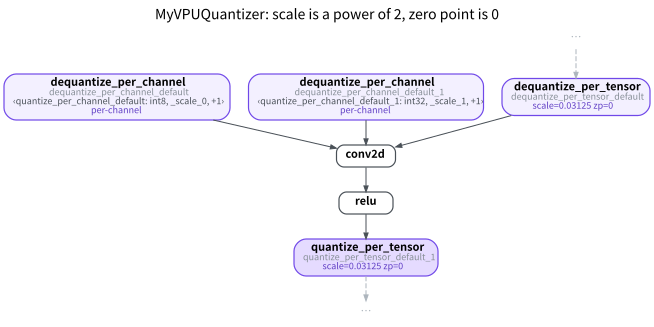

In [4]:
#| echo: false
draw(vpu, focus=["conv2d", "relu"], hops=1, title="MyVPUQuantizer: scale is a power of 2, zero point is 0")

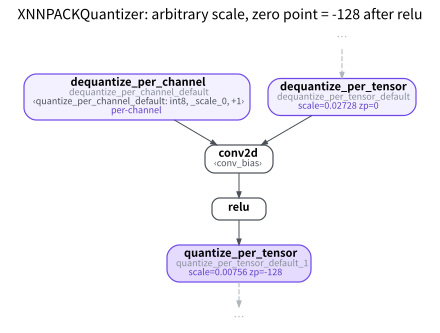

In [5]:
#| echo: false
draw(xnn, focus=["conv2d", "relu"], hops=1, title="XNNPACKQuantizer: arbitrary scale, zero point = -128 after relu")

The extra int32 `dequantize_per_channel` on the VPU graph's conv2d is the bias: `MyVPUQuantizer` quantizes bias to int32 (constraint (5)). The XNNPACK graph has no such dq, because the torchao test-version XNNPACKQuantizer does not annotate bias, so bias stays fp32.

Both graphs are one conv+relu unit; the difference is the numbers on the q/dq. Confirm it in code:

In [6]:
def qparams(gm):
    return [(float(n.args[1]), int(n.args[2])) for n in gm.graph.nodes
            if n.target == torch.ops.quantized_decomposed.quantize_per_tensor.default]


def is_pow2(s):
    return float(torch.log2(torch.tensor(s))).is_integer()


print("VPU quantize_per_tensor (scale, zp):", qparams(vpu))
print("XNNPACK quantize_per_tensor (scale, zp):", [(round(s, 5), z) for s, z in qparams(xnn)])
assert all(is_pow2(s) and z == 0 for s, z in qparams(vpu))
assert not all(is_pow2(s) for s, _ in qparams(xnn)) and qparams(xnn)[-1][1] == -128

VPU quantize_per_tensor (scale, zp): [(0.03125, 0), (0.03125, 0)]
XNNPACK quantize_per_tensor (scale, zp): [(0.02728, 0), (0.00756, -128)]


The XNNPACK graph is perfectly reasonable on a CPU, but it cannot be placed on this VPU: the VPU wants scale $2^k$ and zero point 0. These requirements have to be handed to the algorithm engineer **before quantization**, written as a Quantizer.

## The Eight Constraints and the PT2E Mechanisms

| VPU constraint | PT2E approach | Where in `vpu_quantizer.py` |
|---|---|---|
| (1) only `VPU_OPS` have kernels | other ops get no annotation → stay in fp32 | `VPU_OPS`, the end of `annotate()` |
| (2) activation per-tensor symmetric | `qscheme=per_tensor_symmetric` | `act_spec()` |
| (3) weight per-channel symmetric | `qscheme=per_channel_symmetric` | `weight_spec()` |
| (4) scale is a power of 2 | subclass the observer, override `calculate_qparams()` | `Pow2MinMaxObserver` etc. |
| (5) bias int32, scale = $s_{in} \cdot s_w$ | `DerivedQuantizationSpec` | `bias_spec()` |
| (6) add/cat/pool etc. share one scale between input and output | `SharedQuantizationSpec` | `_add()`, `_cat()`, `_same_scale()` |
| (7) conv/add + relu fused | put the output annotation on the relu, none in between | `fused_relu()` |
| (8) static shape only | `validate()` raises on a SymInt | `validate()` |

This chapter pays off three things M03 set up: `validate()` (M03-3), the `DerivedQuantizationSpec` for the int32 bias (M03-5), and un-annotated ops staying in fp32 (M03-6).

## Why the Hardware Wants These Constraints

| Constraint | What the hardware saves |
|---|---|
| zero point = 0 | the cross terms of an integer conv (see below) |
| scale = $2^k$ | the requant multiplier; only a shift is left (M10-2 C) |
| same scale for input and output | the requant before and after add/pool |
| static shape | runtime memory allocation (planned at compile time, same as M08-2 C) |

The notation follows "Affine Quantization: Scale and Zero Point" in the [M01 overview](../m01_hello_pt2e/00_overview.ipynb): an integer $q$ represents the real number $s\,(q - z)$, where $s$ is the scale and $z$ the zero point. The subscript $x$ means the conv's input activation ($s_x$ is the $s_{in}$ of constraint (5)), and $w$ means the weight.

One output position of a conv is the sum of products $\sum x\,w$ over the kernel window (input channels × kernel height × width). Replace $x$ and $w$ by their integer representations:

$$
\sum x\,w \approx \sum s_x (q_x - z_x) \cdot s_w (q_w - z_w) = s_x s_w \sum (q_x - z_x)(q_w - z_w)
$$

$s_x$ is per-tensor and $s_w$ has a single value within one output channel, so $s_x s_w$ can be pulled out of the sum and left to requant. What the integer kernel has to compute is the remaining sum, which expands to:

$$
\sum (q_x - z_x)(q_w - z_w) = \sum q_x q_w - z_w \sum q_x - z_x \sum q_w + z_x z_w \sum 1 \tag{1}
$$

The first term is a pure integer multiply-accumulate; the other three terms that contain $z$ are the **cross terms** the table refers to:

- When $z_w = 0$, the term with $\sum q_x$ vanishes. $q_x$ is the input and differs at every output position, so this term would have to be accumulated per position at inference time and cannot be saved; the only way out is $z_w = 0$, which makes it 0. The constant term $z_x z_w \sum 1$ goes to 0 as well. The usual weight setting, per-channel symmetric, is exactly this.
- What remains is $z_x \sum q_w$: the activation is per-tensor, $z_x$ is fixed at calibration time, and together with $q_w$ both are constants, so the term can be folded into the bias ahead of time.

Verify equation (1) with random integers, for one output position and 27 products (a 3×3×3 conv):

In [7]:
g = torch.Generator().manual_seed(0)
q_x = torch.randint(-128, 128, (27,), generator=g, dtype=torch.int64)
q_w = torch.randint(-127, 128, (27,), generator=g, dtype=torch.int64)
z_x, z_w = 5, 3
direct = ((q_x - z_x) * (q_w - z_w)).sum()
expanded = (q_x * q_w).sum() - z_w * q_x.sum() - z_x * q_w.sum() + z_x * z_w * len(q_x)
print(f"direct {int(direct)}, expanded {int(expanded)}")
assert direct == expanded

direct -20196, expanded -20196


## The Flow

```text
vpu_quantizer.py      writes the hardware constraints as annotations (MyVPUQuantizer)
  → prepare_pt2e      annotate() annotates, validate() rejects graphs it cannot handle
  → calibrate, convert   the Pow2 observers decide the scales on the Q/DQ graph
  → check_vpu()       backend: reads only the Q/DQ graph and checks the constraints (M10-2)
  → partition()       backend: ops outside the list fall back to CPU (M10-3)
```

The first three steps are what the algorithm engineer does with the Quantizer the backend provides; the last two are what the backend does itself once it receives the Q/DQ graph. All that is handed over in between is the Q/DQ graph, so the backend cannot just trust the quantizer's promise: M10-2 runs the XNNPACK graph through the same check and it violates five of the seven rules.

## Summary and Chapter Map

- A backend Quantizer is hardware constraints translated into annotations: `qscheme`, a custom observer, Shared/Derived, "don't annotate", and `validate()` each handle one kind of constraint.
- Rounding a power-of-2 scale up does not clip more, but the resolution gets up to 2x coarser; in exchange, requant is just a right shift.
- All the backend receives is the Q/DQ graph, so it has to check and partition on its own. The op list decides how many pieces the graph is cut into.

| notebook | Question it answers |
|---|---|
| [M10-1 MyVPUQuantizer](01_vpu_quantizer.ipynb) | How the eight constraints become annotations; the cost of the pow2 observer; `validate()`; which tensors are forced to share a scale |
| [M10-2 Checker pass](02_constraint_checker.ipynb) | Whether a Q/DQ graph is compliant; which rules the XNNPACK graph violates; the requant right-shift amounts |
| [M10-3 Fallback report](03_fallback_report.ipynb) | Which ops fall back to CPU; subgraphs, boundaries and data moved |

What this chapter deliberately skips:

- How much accuracy each constraint costs (M10-1 prints a single SQNR line as a sanity check).
- Integer simulation: M10-2 only computes the right-shift amounts and does not implement conv in integers to compare against the Q/DQ graph; whether it is bit exact depends heavily on the backend implementation (M08 overview, "Numerical Differences from the Q/DQ Graph").
- Whether a single-op subgraph is worth it: that needs measurements on a real device, which this project does not have.

M10 is the last chapter of the learning path. Go back to the [home page](../index.qmd) for the big picture, or to the [M07 overview](../m07_representation_lowering/00_overview.ipynb) to see how the three routes connect to here.

## References

- PyTorch official tutorial: [How to Write a Quantizer for PyTorch 2 Export Quantization](https://docs.pytorch.org/ao/stable/pt2e_quantization/pt2e_quantizer.html)
- [RFC-0019: Extending PyTorch Quantization to Custom Backends](https://github.com/pytorch/rfcs/blob/master/RFC-0019-Extending-PyTorch-Quantization-to-Custom-Backends.md)
- Quantization whitepaper: R. Krishnamoorthi, [Quantizing deep convolutional networks for efficient inference: A whitepaper](https://arxiv.org/abs/1806.08342) (the expansion of integer conv and zero points)